# Visualisatie & Storytelling – Eindopdracht deel 1

**Studenten:**
- Kaan Alhan
- John Shoghnani

## Data inladen

In [1]:
# AI-bron: prompt 1 (dataset inladen), prompt 2 (werkversie A, C en E).
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

bos = pd.read_csv("forest_area_cleaned.csv")
temperatuur = pd.read_csv("city_temperature_preprocessed.csv")


## A – Wereldwijde bosontwikkeling (1990–2020)

Vraag: hoe verandert het totale bosoppervlak in de wereld?

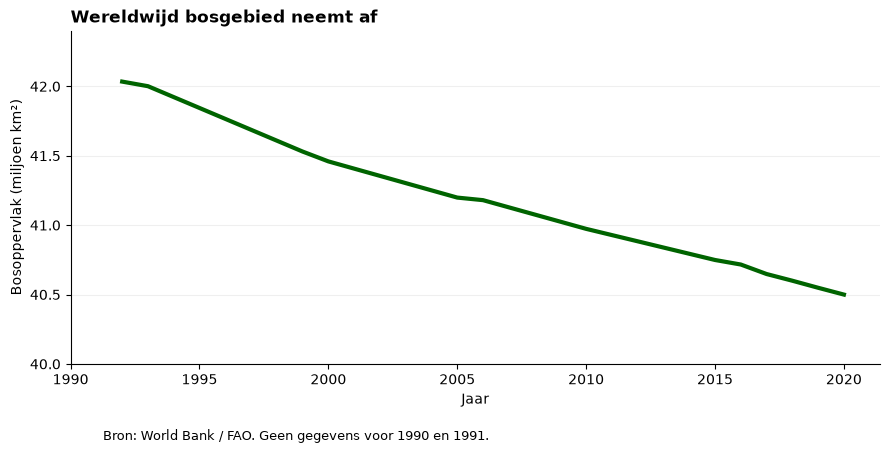

In [2]:
# AI-bron: prompt 2 (werkversie A, C en E).
wereld = bos[bos["area_name"] == "World"]
wereld = wereld[wereld["year"].between(1990, 2020)]

plt.figure(figsize=(9, 4.5))
plt.plot(wereld["year"], wereld["forest_area"] / 1_000_000, color="darkgreen", linewidth=3)
plt.title("Wereldwijd bosgebied neemt af", loc="left", fontweight="bold")
plt.xlabel("Jaar")
plt.ylabel("Bosoppervlak (miljoen km²)")
plt.xticks(range(1990, 2021, 5))
plt.ylim(40, 42.4)
plt.grid(axis="y", alpha=0.2)
plt.gca().spines[["top", "right"]].set_visible(False)
plt.figtext(0.12, 0.01, "Bron: World Bank / FAO. Geen gegevens voor 1990 en 1991.", fontsize=9)
plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()

### Onderbouwing A

Grafiekkeuze: Ik heb gekozen voor een lijngrafiek omdat het gaat om veranderingen over tijd. Met een lijngrafiek is het overzichtelijker om te zien wat er na zoveel jaar gebeurt. Een staafdiagram is hiervoor minder handig.

Context: De VN-leiders kunnen zien dat er met de tijd een steeds groter probleem ontstaat. Tussen 1992 en 2020 is er ongeveer 1,53 miljoen km² aan bos verdwenen. Ze kunnen maatregelen nemen om hier een stokje voor te steken.

Clutter: Ik heb de lijnen boven en rechts weggehaald, geen legenda toegevoegd en alleen lichte horizontale hulplijnen gebruikt. Ook worden de jaartallen om de vijf jaar weergegeven, zodat de grafiek overzichtelijker wordt.

Visuele focus: Ik heb gekozen voor groen omdat het over het milieu gaat. De lijn is dik gemaakt omdat deze duidelijk zichtbaar moet zijn en het belangrijkste aandachtspunt is. De achtergrond is rustig gehouden, omdat het anders onnodig druk wordt en voor afleiding zorgt.

## B – Bosgebied per inkomensgroep



In [31]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

forest = pd.read_csv("forest_area_cleaned.csv")

income_groups = [
    "Low income",
    "Lower middle income",
    "Middle income",
    "Upper middle income",
    "High income"
]

forest_b = forest[forest["area_name"].isin(income_groups)]
forest_b = forest_b[forest_b["year"].between(1992, 2020)]

forest_b = forest_b.pivot(
    index="year",
    columns="area_name",
    values="forest_area"
)

forest_b = (forest_b / forest_b.loc[1992] - 1) * 100

display(forest_b.round(2))

area_name,High income,Low income,Lower middle income,Middle income,Upper middle income
year,,,,,
1992,0.00,0.00,0.00,0.00,0.00
1993,0.51,-0.48,-0.27,-0.24,-0.23
1994,0.58,-0.96,-0.54,-0.47,-0.45
1995,0.64,-1.44,-0.80,-0.71,-0.68
1996,0.71,-1.92,-1.07,-0.94,-0.91
1997,0.77,-2.40,-1.34,-1.18,-1.13
1998,0.84,-2.88,-1.61,-1.42,-1.36
1999,0.91,-3.35,-1.87,-1.65,-1.59
2000,1.05,-3.83,-2.14,-1.89,-1.81


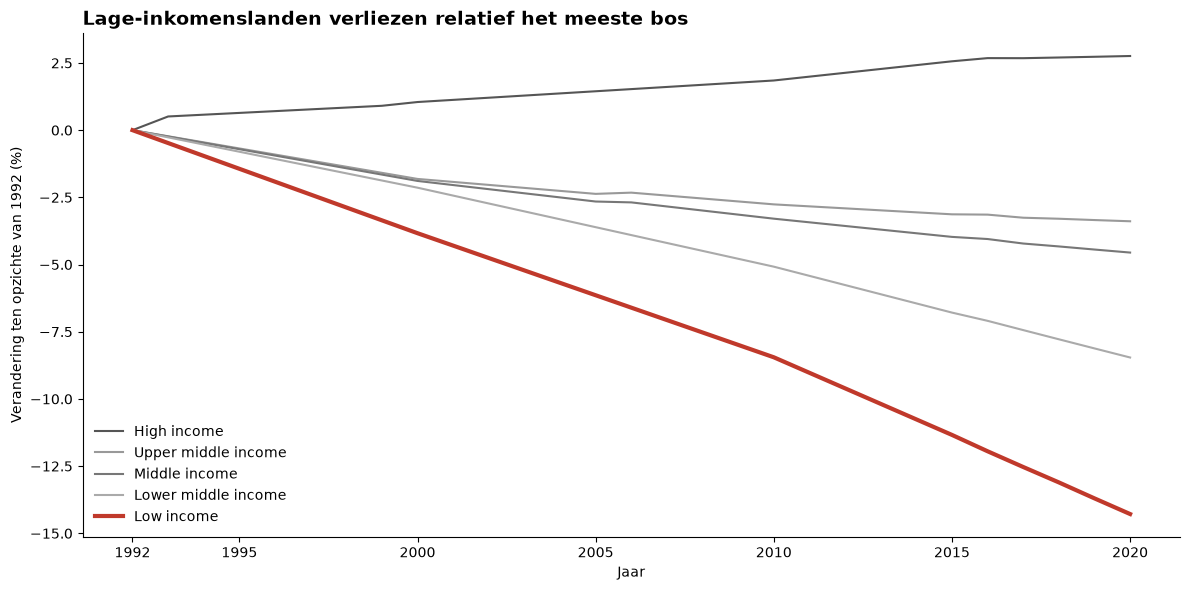

In [32]:
plt.figure(figsize=(12, 6))

plt.plot(forest_b.index, forest_b["High income"],
         color="#555555", label="High income")

plt.plot(forest_b.index, forest_b["Upper middle income"],
         color="#999999", label="Upper middle income")

plt.plot(forest_b.index, forest_b["Middle income"],
         color="#777777", label="Middle income")

plt.plot(forest_b.index, forest_b["Lower middle income"],
         color="#AAAAAA", label="Lower middle income")

plt.plot(forest_b.index, forest_b["Low income"],
         color="#C0392B", linewidth=3, label="Low income")

plt.title(
    "Lage-inkomenslanden verliezen relatief het meeste bos",
    fontsize=14,
    fontweight="bold",
    loc="left"
)

plt.xlabel("Jaar")
plt.ylabel("Verandering ten opzichte van 1992 (%)")
plt.xticks([1992, 1995, 2000, 2005, 2010, 2015, 2020])

plt.legend(frameon=False, loc="lower left")
plt.grid(False)

sns.despine()
plt.tight_layout()
plt.show()

### Onderbouwing grafiek B

**Grafiekkeuze:** Ik heb gekozen voor een lijngrafiek met
procentuele veranderingen, omdat de inkomensgroepen sterk
verschillen in absolute bosoppervlakte. Door alle groepen
vanaf hetzelfde referentiejaar te vergelijken, worden
dalende en stijgende trends duidelijker zichtbaar.

**Context:** Tussen 1992 en 2020 verloren lage-inkomenslanden
ongeveer 14,3% van hun bosoppervlakte, terwijl hoge-inkomenslanden
een stijging van ongeveer 2,8% laten zien. VN-leiders kunnen
deze informatie gebruiken om te onderzoeken waar extra
financiële en technische ondersteuning bij bosbescherming
nodig is.

**Clutter:** Alle rasterlijnen, de bovenste en rechterrand
en het kader rondom de legenda zijn verwijderd. Hierdoor
ligt de nadruk op de ontwikkeling van de lijnen.

**Preattentive attributes:** De lijn van Low income is rood
en dikker gemaakt dan de overige lijnen, omdat deze groep
het grootste relatieve bosverlies heeft. De overige lijnen
zijn grijs om minder aandacht te trekken.

Voor Middle income en Upper middle
income ontbreken gegevens uit 1990 en 1991. Daarom is 1992
gekozen als gezamenlijk referentiejaar. Er zijn geen
ontbrekende waarden ingevuld of geschat.

## C – Bosontwikkeling in drie landen en de wereld (2018–2020)

Vraag: hebben alle landen dezelfde ontwikkeling als de wereld?

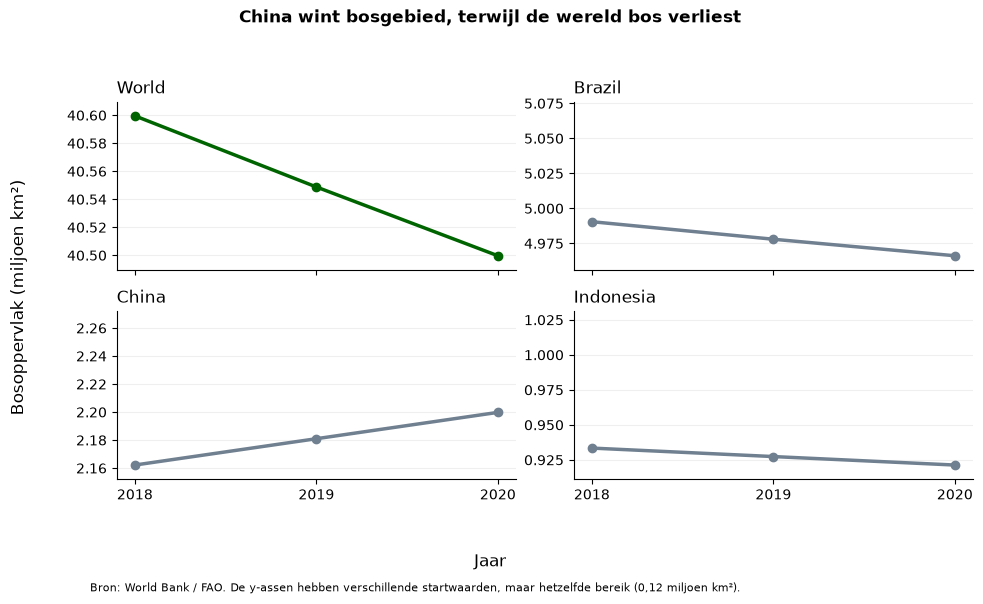

In [5]:
# AI-bron: prompt 2 (werkversie A, C en E).
landen = ["World", "Brazil", "China", "Indonesia"]
vergelijking = bos[bos["area_name"].isin(landen) & bos["year"].between(2018, 2020)]

fig, assen = plt.subplots(2, 2, figsize=(10, 6), sharex=True)

for land, ax in zip(landen, assen.flat):
    gegevens = vergelijking[vergelijking["area_name"] == land]
    oppervlakte = gegevens["forest_area"] / 1_000_000
    kleur = "darkgreen" if land == "World" else "slategray"
    ax.plot(gegevens["year"], oppervlakte, color=kleur, linewidth=2.5, marker="o")
    ax.set_title(land, loc="left")
    ax.set_xticks([2018, 2019, 2020])
    ax.set_ylim(oppervlakte.min() - 0.01, oppervlakte.min() + 0.11)
    ax.ticklabel_format(axis="y", style="plain", useOffset=False)
    ax.grid(axis="y", alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("China wint bosgebied, terwijl de wereld bos verliest", fontweight="bold")
fig.supylabel("Bosoppervlak (miljoen km²)")
fig.supxlabel("Jaar", y=0.045)
fig.text(0.1, 0.01, "Bron: World Bank / FAO. De y-assen hebben verschillende startwaarden, maar hetzelfde bereik (0,12 miljoen km²).", fontsize=8)
plt.tight_layout(rect=[0.03, 0.08, 1, 0.94])
plt.show()

## Onderbouwing C

**Grafiekkeuze:** Ik heb gekozen voor vier verschillende lijngrafieken omdat de bosoppervlaktes sterk verschillen. Als we alles in één lijngrafiek zouden zetten, zouden de veranderingen per land minder goed zichtbaar zijn. De aparte grafieken hebben hetzelfde verticale bereik, waardoor we de veranderingen goed met elkaar kunnen vergelijken.

**Context:**
- Wereld: bosgebied neemt af.
- Brazilië: bosgebied neemt af.
- Indonesië: bosgebied neemt af.
- China: bosgebied neemt toe.

VN-leiders kunnen onderzoeken waarom China het beter doet dan de andere landen en aan de hand daarvan kijken welke maatregelen andere landen kunnen nemen.

**Clutter:**
- Geen legenda, omdat de landnamen boven de grafieken staan.
- Bovenste en rechterranden verwijderd.
- Lichte horizontale hulplijnen.
- Alle grafieken hebben dezelfde opmaak.

Hierdoor zijn de grafieken rustiger en makkelijker te vergelijken.

**Visuele focus:**
- Groen: benadrukt de wereld als vergelijkingspunt.
- Grijs: geeft de landen minder nadruk.
- Dikke lijnen: maken de trends duidelijk zichtbaar.
- Ronde punten: benadrukken de metingen per jaar.
- Titel: vestigt de aandacht op China, omdat daar het bosgebied juist toeneemt.

## D – Bosgebied in 2020

In [40]:
groups = [
    "World",
    "Low income",
    "Lower middle income",
    "Middle income",
    "Upper middle income",
    "High income"
]

forest_d = forest[forest["area_name"].isin(groups)]
forest_d = forest_d[forest_d["year"] == 2020]

forest_d = forest_d.set_index("area_name")

display(forest_d)

,area_code,year,forest_area
area_name,,,
High income,HIC,2020,10510106.5
Low income,LIC,2020,2991863.4
Lower middle income,LMC,2020,5845811.0
Middle income,MIC,2020,26535408.8
Upper middle income,UMC,2020,20689597.8
World,WLD,2020,40499687.7


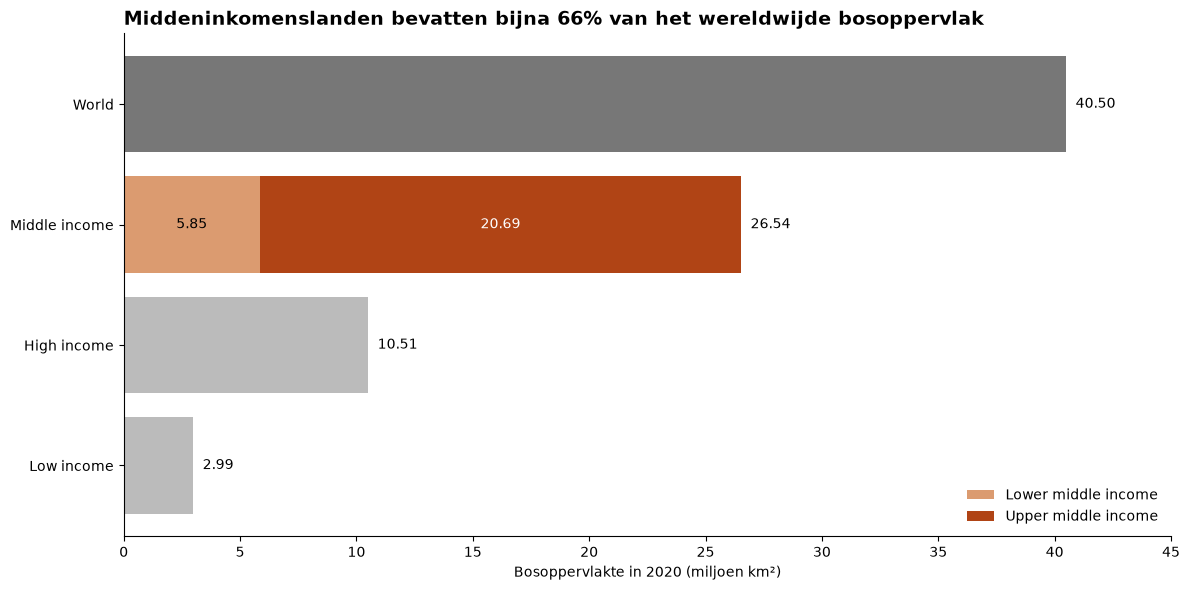

In [41]:
world = forest_d.loc["World", "forest_area"] / 1000000
low = forest_d.loc["Low income", "forest_area"] / 1000000
lower_middle = forest_d.loc["Lower middle income", "forest_area"] / 1000000
middle = forest_d.loc["Middle income", "forest_area"] / 1000000
upper_middle = forest_d.loc["Upper middle income", "forest_area"] / 1000000
high = forest_d.loc["High income", "forest_area"] / 1000000

plt.figure(figsize=(12, 6))

plt.barh("World", world, color="#777777")
plt.barh("Middle income", lower_middle, color="#DB9B70",
         label="Lower middle income")

plt.barh("Middle income", upper_middle, left=lower_middle,
         color="#B04415", label="Upper middle income")

plt.barh("High income", high, color="#BBBBBB")
plt.barh("Low income", low, color="#BBBBBB")

# Waarden naast de balken
plt.text(world + 0.4, 0, f"{world:.2f}", va="center")
plt.text(middle + 0.4, 1, f"{middle:.2f}", va="center")
plt.text(high + 0.4, 2, f"{high:.2f}", va="center")
plt.text(low + 0.4, 3, f"{low:.2f}", va="center")

# Waarden binnen de gestapelde balk
plt.text(lower_middle / 2, 1, f"{lower_middle:.2f}",
         ha="center", va="center")

plt.text(lower_middle + upper_middle / 2, 1,
         f"{upper_middle:.2f}",
         ha="center", va="center", color="white")

plt.title(
    "Middeninkomenslanden bevatten bijna 66% van het wereldwijde bosoppervlak",
    fontsize=14,
    fontweight="bold",
    loc="left"
)

plt.xlabel("Bosoppervlakte in 2020 (miljoen km²)")
plt.xlim(0, 45)

plt.gca().invert_yaxis()

plt.legend(frameon=False, loc="lower right")

plt.grid(False)
sns.despine()
plt.tight_layout()

plt.show()

### Onderbouwing grafiek D

**Grafiekkeuze:** Ik heb gekozen voor een horizontaal
staafdiagram met een gestapelde balk voor Middle income.
Hierdoor kunnen de absolute bosoppervlaktes in 2020
worden vergeleken, terwijl ook zichtbaar wordt hoe
Middle income is opgebouwd uit twee subgroepen.

**Context:** Middeninkomenslanden bevatten in 2020
26,54 miljoen km² aan bos, ongeveer 66% van het
wereldwijde bosoppervlak. Hiervan bevindt 20,69 miljoen
km² zich in Upper middle income-landen en 5,85 miljoen
km² in Lower middle income-landen.

Voor VN-leiders benadrukt dit het belang van samenwerking
met middeninkomenslanden bij internationale maatregelen
voor bosbescherming. Het grote aandeel bosoppervlakte
betekent echter niet automatisch dat hier ook de meeste
ontbossing plaatsvindt.

**Clutter:** Ik heb alle rasterlijnen, overbodige randen
en het kader rondom de legenda verwijderd. De twee
middeninkomensgroepen zijn verwerkt in één gestapelde
balk, waardoor onnodige herhaling wordt voorkomen.
De exacte waarden staan direct bij de balken.

**Preattentive attributes:** De middeninkomensgroepen
zijn weergegeven in twee oranjerode tinten. Hierdoor
trekken ze meer aandacht dan de grijze balken.
De twee tinten maken tegelijkertijd duidelijk dat
het om verschillende subgroepen binnen dezelfde
inkomenscategorie gaat.

Lower middle income en Upper
middle income vormen samen Middle income. Door deze
groepen binnen dezelfde balk weer te geven, wordt
dubbeltelling voorkomen. World is het wereldtotaal
en dient uitsluitend als vergelijkingspunt.
De inkomensgroepen tellen in de dataset niet exact
op tot het wereldtotaal.

## E – Gemiddelde temperatuur per jaar (1995–2019)

Vraag: hoe ontwikkelt de gemiddelde temperatuur zich volgens de beschikbare stadsmetingen?

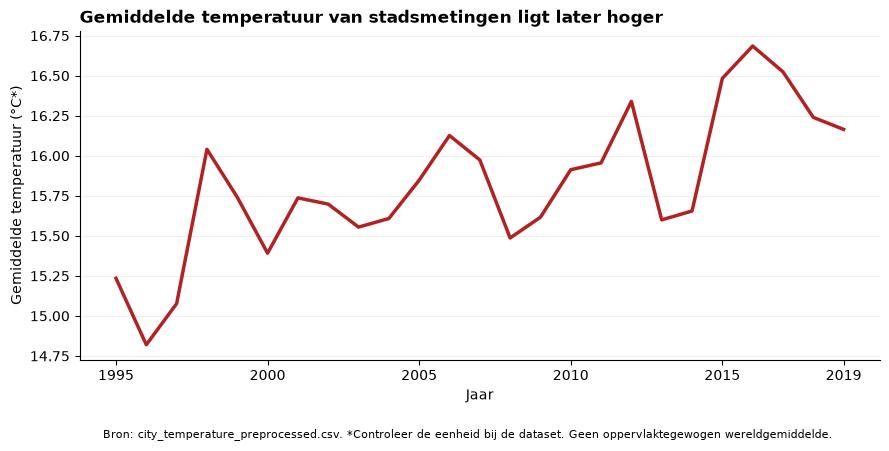

In [8]:
# AI-bron: prompt 2 (werkversie A, C en E).
temperatuur_periode = temperatuur[temperatuur["Year"].between(1995, 2019)]
jaargemiddelde = temperatuur_periode.groupby("Year")["AvgTemperature"].mean()

plt.figure(figsize=(9, 4.5))
plt.plot(jaargemiddelde.index, jaargemiddelde.values, color="firebrick", linewidth=2.5)
plt.title("Gemiddelde temperatuur van stadsmetingen ligt later hoger", loc="left", fontweight="bold")
plt.xlabel("Jaar")
plt.ylabel("Gemiddelde temperatuur (°C*)")
plt.xticks([1995, 2000, 2005, 2010, 2015, 2019])
plt.grid(axis="y", alpha=0.2)
plt.gca().spines[["top", "right"]].set_visible(False)
plt.figtext(0.12, 0.015, "Bron: city_temperature_preprocessed.csv. *Controleer de eenheid bij de dataset. Geen oppervlaktegewogen wereldgemiddelde.", fontsize=8)
plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.show()

### Onderbouwing E

Grafiekkeuze: Deze lijngrafiek laat duidelijk zien hoe de gemiddelde temperatuur over tijd verandert.

Context: Je ziet dat de gemiddelde temperatuur van de stadsmetingen later hoger ligt. Hierdoor kunnen de VN-leiders inzien dat er maatregelen genomen moeten worden om verdere opwarming tegen te gaan.

Clutter:
- Geen onnodige legenda.
- Bovenste en rechterrand verwijderd.
- Lichte horizontale hulplijnen.
- Beperkt aantal jaartallen.

Dit maakt de grafiek veel minder druk en daardoor overzichtelijker.

Visuele focus:
- Rode kleur, omdat rood met warmte wordt geassocieerd.
- Dikke lijn om de aandacht te trekken.
- Rustige achtergrond om afleiding te voorkomen.

## F – Maandelijkse temperatuur Nederland


In [28]:
temperature = pd.read_csv("city_temperature_preprocessed.csv")

temperature_f = temperature[temperature["Country"] == "The Netherlands"]

display(temperature_f)

,Region,Country,City,Month,Day,Year,AvgTemperature
767088,Europe,The Netherlands,Amsterdam,1,1,1995,3.1
767089,Europe,The Netherlands,Amsterdam,1,2,1995,3.7
767090,Europe,The Netherlands,Amsterdam,1,3,1995,0.7
767091,Europe,The Netherlands,Amsterdam,1,4,1995,-1.6
767092,Europe,The Netherlands,Amsterdam,1,5,1995,-3.4
...,...,...,...,...,...,...,...
776185,Europe,The Netherlands,Amsterdam,12,27,2019,4.0
776186,Europe,The Netherlands,Amsterdam,12,28,2019,0.7
776187,Europe,The Netherlands,Amsterdam,12,29,2019,1.5
776188,Europe,The Netherlands,Amsterdam,12,30,2019,4.6


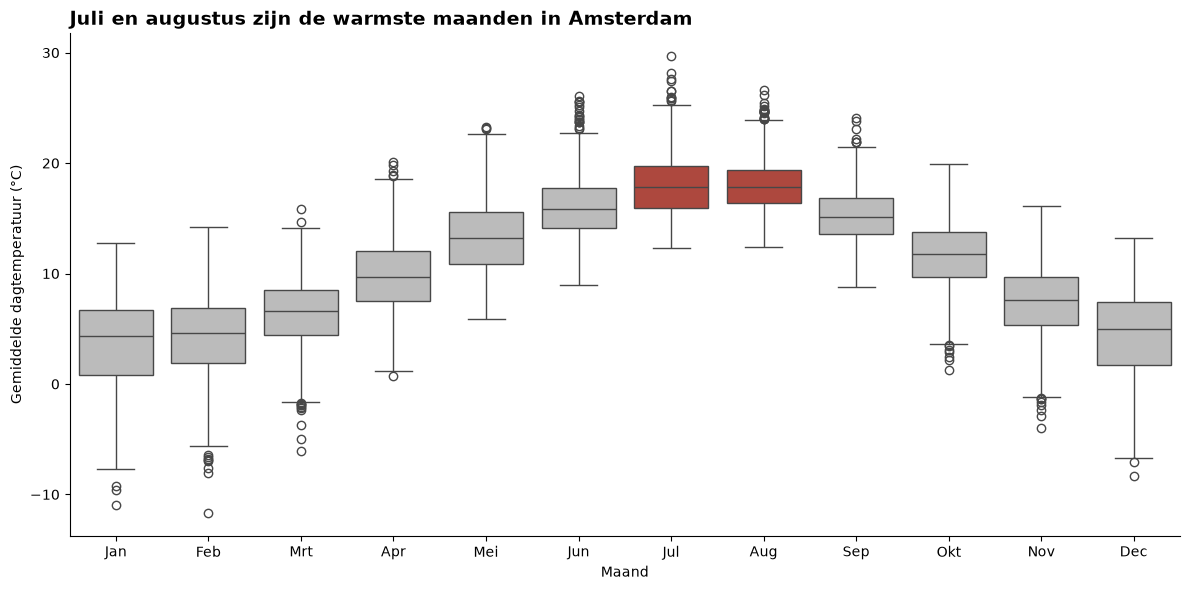

In [30]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=temperature_f,
    x="Month",
    y="AvgTemperature",
    hue="Month",
    palette=[
        "#BBBBBB", "#BBBBBB", "#BBBBBB",
        "#BBBBBB", "#BBBBBB", "#BBBBBB",
        "#C0392B", "#C0392B", "#BBBBBB",
        "#BBBBBB", "#BBBBBB", "#BBBBBB"
    ],
    legend=False
)

plt.title(
    "Juli en augustus zijn de warmste maanden in Amsterdam",
    fontsize=14,
    fontweight="bold",
    loc="left"
)

plt.xlabel("Maand")
plt.ylabel("Gemiddelde dagtemperatuur (°C)")

plt.xticks(
    range(12),
    ["Jan", "Feb", "Mrt", "Apr", "Mei", "Jun",
     "Jul", "Aug", "Sep", "Okt", "Nov", "Dec"]
)

sns.despine()
plt.tight_layout()

plt.show()

### Onderbouwing grafiek F

**Grafiekkeuze:** Ik heb gekozen voor twaalf boxplots
omdat temperaturen binnen dezelfde maand kunnen
verschillen. Een lijngrafiek met alleen gemiddelden
zou deze verschillen verbergen. De boxplots laten
per maand de mediaan, het middelste deel van de
metingen, de spreiding en eventuele uitschieters zien.

**Context:** Uit 9.102 dagelijkse temperatuurmetingen
in Amsterdam tussen 1995 en 2019 blijkt dat juli
en augustus de warmste maanden zijn. Beide maanden
hebben een mediane dagtemperatuur van 17,8 °C.
In januari is dit slechts 4,3 °C. Het hoogste
gemeten daggemiddelde bedraagt 29,7 °C.

VN-leiders kunnen deze informatie gebruiken bij het
bespreken van klimaatadaptatie in stedelijke gebieden.
De resultaten geven aanleiding om voorbereiding op
hitte, zoals verkoeling in steden, bescherming van
kwetsbare inwoners en hitteplannen, vooral vóór de
zomermaanden te organiseren.

**Clutter:** Ik heb alle rasterlijnen, overbodige
randen, maatstreepjes onder de maanden en de legenda
verwijderd. De maanden zijn chronologisch geordend
en afgekort. De belangrijkste mediane temperatuur
staat direct boven de twee gemarkeerde maanden.

**Preattentive attributes:** Juli en augustus zijn
rood gemaakt, terwijl de overige maanden grijs zijn.
Het kleurcontrast trekt direct de aandacht naar de
warmste periode. De verticale positie van de boxplots
maakt temperatuurverschillen zichtbaar en de hoogte
van de boxen laat verschillen in spreiding zien.

**Beperking:** De gegevens zijn uitsluitend afkomstig
uit Amsterdam. De grafiek toont seizoensverschillen,
maar bewijst niet dat Nederland door klimaatverandering
warmer wordt. Daarvoor is een analyse van de
temperatuurontwikkeling over meerdere jaren nodig.

## Impact-evaluatie AI – nog zelf aanvullen

AI is ingezet voor uitleg over de opdracht, GitHub, het inladen van data en het voorbereiden van voorbeeldcode en ontwerpkeuzes voor A, C en E. De voorbeeldcode is uitgevoerd met de aangeleverde bestanden. De temperatuur-eenheid is niet gedocumenteerd in het CSV-bestand en moet nog bij de cursusbron worden geverifieerd. Het gemiddelde is niet geografisch gewogen.

**Vul zelf aan:** welke onderdelen heb je daadwerkelijk gebruikt, zelfstandig geschreven of aangepast? Welke positieve en negatieve effecten heb je ervaren? Hoe heb je de resultaten gecontroleerd en de beperkingen aangepakt? Controleer dat maximaal 50% van alle code in het gezamenlijke notebook letterlijk of vrijwel letterlijk uit bronnen komt.

## GenAI-impactevaluatie

### Gebruik van GenAI

Tijdens het maken van opdrachten B, D en F heb ik ChatGPT gebruikt als hulpmiddel bij het schrijven en verbeteren van Python-code, het ontwerpen van visualisaties en het onderbouwen van mijn keuzes. Daarnaast heb ik AI gebruikt om ontvangen feedback te verwerken.

### Positieve impact

Het gebruik van GenAI heeft geholpen bij het verbeteren van de leesbaarheid van de grafieken, het verwijderen van clutter en het toepassen van preattentive attributes. Ook heeft het geholpen bij het bedenken van verschillende oplossingen voor ontbrekende gegevens en overlappende inkomensgroepen.

### Negatieve impact en beperkingen

Niet alle gegenereerde oplossingen waren direct bruikbaar. Sommige grafieken werden onnodig ingewikkeld of voldeden niet volledig aan de eisen van de opdracht. Bij grafiek D werden bijvoorbeeld eerst inkomensgroepen weggelaten, terwijl deze juist weergegeven moesten worden.

### Eigen bijdrage

Ik heb de voorgestelde oplossingen beoordeeld en aangegeven welke onderdelen verbeterd moesten worden. Daarbij heb ik rekening gehouden met de opdracht, de ontvangen feedback en de doelgroep. Uiteindelijk heb ik verschillende ontwerpen vergeleken en bepaald welke visualisaties het beste aansloten bij de boodschap die ik wilde overbrengen.

## Referenties – nog aanvullen
- World Bank. (z.d.). *Forest area (sq. km)*. https://data.worldbank.org/indicator/AG.LND.FRST.K2?view=chart (voorbewerkte dataset `forest_area_cleaned.csv` via Brightspace).
- [Auteur/organisatie en jaar controleren]. *city_temperature_preprocessed.csv* [Dataset]. Brightspace, Visualisatie & Storytelling.

## Literatuur
Knaflic, C. N. (2015). Storytelling with data: A data visualization guide for business professionals. John Wiley & Sons.

## Generatieve AI
- ChatGPT (GPT-6.2, 2026). Prompt 1: Dataset inladen en filteren. [Voeg de echte gedeelde gesprekslink toe].
- ChatGPT (GPT-6.2, 2026). Prompt 2: Werkversie opdrachten A, C en E (met rubric). [Voeg de echte gedeelde gesprekslink toe].
- ChatGPT GPT-6.2, 2026. Prompt 3: Bosoppervlakte per inkomensniveau visualiseren
- ChatGPT GPT-6.2, 2026. Prompt 4: Ontbrekende gegevens en procentuele veranderingen
- ChatGPT GPT-6.2, 2026. Prompt 5: Bosoppervlakte per inkomensniveau in 2020
- ChatGPT GPT-6.2, 2026. Prompt 6: Overlappende inkomensgroepen visualiseren
- ChatGPT GPT-6.2, 2026. Prompt 7: Maandelijkse temperaturen in Nederland visualiseren